In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import python_anesthesia_simulator as pas

In [11]:
# Load data
data = pd.read_csv('data/database.csv')
data.rename(columns={'BIS_Eleveld': 'BIS_sim'}, inplace=True)
data['TPR'] = (data['MAP'] / (data['HR'] * data['SV'])).clip(0, 0.04)
data['TPR_sim'] = (data['MAP_sim'] / (data['HR_sim'] * data['SV_sim'])).clip(0, 0.04)
print(f"Number of case: {data.caseid.nunique()}")

print(f"mean propofol concentration: {data['Ce_prop'].median():.2f} µg/mL")
print(f"mean remifentanil concentration: {data['Ce_remi'].median():.2f} ng/mL")
print(f"mean BIS value: {data['BIS'].median():.2f}")


Number of case: 54
mean propofol concentration: 3.57 µg/mL
mean remifentanil concentration: 3.90 ng/mL
mean BIS value: 42.14


In [12]:
data_induction = data.query('Time<600 & Time>300')

print(f"mean propofol concentration: {data_induction['Ce_prop'].median():.2f} µg/mL")
print(f"mean remifentanil concentration: {data_induction['Ce_remi'].median():.2f} ng/mL")
print(f"mean BIS value: {data_induction['BIS'].median():.2f}")

mean propofol concentration: 3.37 µg/mL
mean remifentanil concentration: 3.94 ng/mL
mean BIS value: 55.71


In [13]:
data.bis_base.mean()

np.float64(46.994073496727104)

In [14]:
available_bis_model = [
    'Eleveld',
    'Bouillon',
    'Vanluchene',
    'Fuentes',
    'Yumuk',
    ]
for model in available_bis_model:
    bis = []
    for caseid, data_case in data.groupby('caseid'):
        bis_model = pas.BIS_model(hill_model=model, age=data_case['age'].iloc[0])
        # e0_init = bis_model.E0s
        # bis_model.E0 = data_case['BIS'].iloc[0]
        # bis_model.Emax *= bis_model.E0 / e0_init
        bis_case = bis_model.compute_bis(data_case['Ce_prop'].values, data_case['Ce_remi'].values)
        bis+=list(bis_case)
    data.insert(0, f"BIS_{model}", bis)

bis = []
model='Bouillon'
for caseid, data_case in data.groupby('caseid'):
    bis_model = pas.BIS_model(hill_model=model, age=data_case['age'].iloc[0])
    e0_init = bis_model.E0
    bis_model.E0 = data_case['BIS'].iloc[0]
    bis_model.Emax *= bis_model.E0 / e0_init
    bis_case = bis_model.compute_bis(data_case['Ce_prop'].values, data_case['Ce_remi'].values)
    bis+=list(bis_case)
data.insert(0, "BIS_Bouillon_identif", bis)

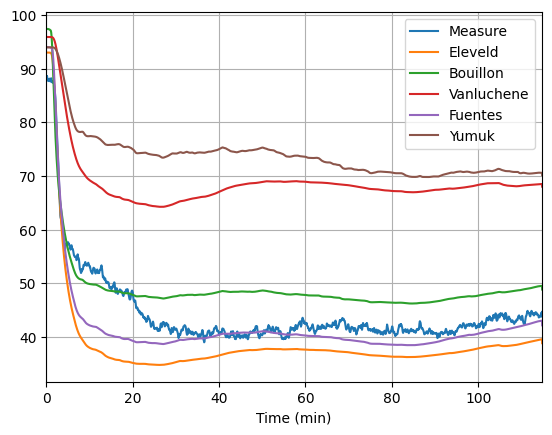

In [15]:
min_case_duration = data.groupby('caseid')['Time'].max().min()

data['Time'] = data.groupby('caseid')['Time'].transform(lambda x: x - x.min())
intub_median = np.median(data['intubation_time'].unique())
opstart_median = np.median(data['opstart'].unique())
bis_mean = data.groupby("Time")["BIS"].mean()
bis_std = data.groupby("Time")["BIS"].std()
x = bis_mean.index/60
plt.plot(x, bis_mean, label='Measure')
for model in available_bis_model:
    bis_mean = data.groupby("Time")[f"BIS_{model}"].mean().values
    plt.plot(x, bis_mean, label=model)
# plt.plot(x, data.groupby("Time")["BIS_Bouillon_identif"].mean().values, label='Bouillon (E0 identified)', linestyle='--', color='green')

plt.grid()
plt.legend(prop={'size': 10}, loc=1)
plt.xlim([0,min_case_duration/60])
plt.xlabel('Time (min)')
plt.savefig('output/bis_comparison.pdf', dpi=300)
plt.show()

In [16]:
mdpe_model = {}
mdape_model = {}
available_bis_model.append('Bouillon_identif')
for model in available_bis_model:
    mdpe_model_list = []
    mdape_model_list = []
    length_list = []

    for caseid, data_case in data.groupby('caseid'):
        PE = 100 * ((data_case['BIS'] - data_case[f"BIS_{model}"])/data_case['BIS']).values
        MDPE_case = np.median(PE)
        MDAPE_case = np.median(np.abs(PE))
        var_mdpe_case = np.var(PE)
        mdpe_model_list.append(MDPE_case)
        mdape_model_list.append(MDAPE_case)
        length_list.append(len(PE))
    
    MDPE_model = np.sum(np.multiply(mdpe_model_list,length_list)) / np.sum(length_list)
    MDAPE_model = np.sum(np.multiply(mdape_model_list,length_list)) / np.sum(length_list)
    mdpe_model[model] = MDPE_model
    mdape_model[model] = MDAPE_model
print(mdpe_model)
print(mdape_model)

{'Eleveld': np.float64(9.37573709020266), 'Bouillon': np.float64(-14.683504893284455), 'Vanluchene': np.float64(-63.025873825897484), 'Fuentes': np.float64(2.5269613054026605), 'Yumuk': np.float64(-72.2156451437246), 'Bouillon_identif': np.float64(-3.3547701370105174)}
{'Eleveld': np.float64(19.411523513172853), 'Bouillon': np.float64(19.745967483035432), 'Vanluchene': np.float64(63.04485616225853), 'Fuentes': np.float64(16.35579245196005), 'Yumuk': np.float64(73.38332603164677), 'Bouillon_identif': np.float64(17.275029170657294)}
